# PathSnap - 05 HMM + Viterbi route reconstruction

Implementation: `src/hmm.py`.

* **Hidden states:** at GPS point *i*, the candidate arcs of that point (K <= 8, R = 50 m). Each state is an arc id, so the
  candidate-to-road-segment correspondence is preserved end to end.
* **Emission:** `EMIT_W * log(p)`, where *p* is the tuned LightGBM probability that the candidate is the true arc (floored at 1e-4).
* **Transition:** `-|route_distance - straight_distance| / BETA` (Newson & Krumm). The route distance follows the **directed** road graph from the
  projection on arc *a* to the projection on arc *b* (bounded Dijkstra, cached). Unreachable means the transition is impossible. Staying on the
  same arc is allowed, with up to 15 m of apparent backwards movement tolerated as GPS noise.
* **Viterbi:** `delta_i(b) = emit_i(b) + max_a [delta_{i-1}(a) + trans(a, b)]`, with back-pointers, then backtracking.
* **Gaps:** time gaps > 60 s split the trip into independent segments (each decoded separately). Points without candidates are skipped,
  and the transition is computed between the surrounding observed points.
* **Disconnected candidates:** if no transition is possible, the chain restarts from the best previous state (counted as a *break*).

**Decoder parameters (BETA, EMIT_W)** are tuned on **out-of-fold** probabilities of the 80 train trips (GroupKFold 5), so the classifier never
scores trips it was trained on. student_test is used only for the final comparison.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import folium, joblib
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold

sys.path.insert(0, str(Path.cwd().parent / "src"))
import hmm
from data import load_trip, list_trips
from features import FEATURES, prepare
from metrics import route_continuity, load_arcs
from models import SEED

ROOT = Path.cwd().parent
FEAT, ART = ROOT / "outputs" / "features", ROOT / "artifacts"
OUT = ROOT / "outputs" / "hmm"; (OUT / "plots").mkdir(parents=True, exist_ok=True); (OUT / "maps").mkdir(parents=True, exist_ok=True)
cfg = json.load(open(ART / "model_config.json")); model = joblib.load(ART / "model.joblib")
ctr = pd.read_parquet(FEAT / "candidates_train.parquet"); ptr = pd.read_parquet(FEAT / "points_train.parquet")
cte = pd.read_parquet(FEAT / "candidates_student_test.parquet"); pte = pd.read_parquet(FEAT / "points_student_test.parquet")
arcs = {**load_arcs("train"), **load_arcs("student_test")}
print(cfg["model"], cfg["params"])

LightGBM {'num_leaves': 138, 'learning_rate': 0.02630748751678775, 'n_estimators': 600, 'min_child_samples': 12, 'subsample': 0.5774912745607391, 'colsample_bytree': 0.9907796453307647, 'reg_lambda': 9.986332503136188}


## 1. Out-of-fold probabilities on train (for decoder tuning)

In [2]:
trips = ctr.trip_id.unique(); oof = np.zeros(len(ctr))
for tr_i, va_i in GroupKFold(n_splits=5).split(trips, groups=trips):
    tr_m, va_m = ctr.trip_id.isin(trips[tr_i]).values, ctr.trip_id.isin(trips[va_i]).values
    a = ctr[tr_m & (ctr.label >= 0).values]
    m = LGBMClassifier(**cfg["params"], subsample_freq=1, random_state=SEED, verbose=-1).fit(a[FEATURES], a.label)
    oof[va_m] = m.predict_proba(ctr.loc[va_m, FEATURES])[:, 1]
ctr["prob"] = oof
cte["prob"] = model.predict_proba(cte[FEATURES])[:, 1]

In [3]:
PREP = {}
def prep(part, tid):
    if (part, tid) not in PREP:
        p = prepare(load_trip(part, tid)); PREP[(part, tid)] = (p, hmm.RoadGraph(p["u"], p["v"], p["arc_len"]))
    return PREP[(part, tid)]

def run(part, cand, pts, beta, emit_w, trip_ids=None):
    rows, preds = [], []
    for tid in trip_ids if trip_ids is not None else pts.trip_id.unique():
        p, g = prep(part, tid)
        c = cand[cand.trip_id == tid]; q = pts[pts.trip_id == tid]
        t0 = time.time(); pred, br = hmm.decode(p, c, c.prob.values, beta=beta, emit_w=emit_w, graph=g); dt = time.time() - t0
        top = c.sort_values("prob", ascending=False, kind="stable").drop_duplicates("point_idx").set_index("point_idx").arc_id
        clf = top.reindex(range(p["n"])).fillna(-1).astype(int).values
        true = q.true_arc.values; lab = true >= 0
        ref = set(true[lab]) # reference arcs that GPS points were aligned to
        def road_ok(pr):   # same arc, or its exact reverse twin (same road, other direction)
            x, t = np.maximum(pr[lab], 0), true[lab]
            return ((pr[lab] == t) | ((pr[lab] >= 0) & (p["u"][x] == p["v"][t]) & (p["v"][x] == p["u"][t]))).mean()
        def route_f1(pr):
            s = set(pr[pr >= 0]); tp = len(s & ref)
            return 2 * tp / max(len(s) + len(ref), 1)
        rows.append({"trip_id": tid, "points": p["n"], "labelled": int(lab.sum()), "breaks": br, "decode_s": dt,
                     "clf_top1": (clf[lab] == true[lab]).mean(), "hmm_top1": (pred[lab] == true[lab]).mean(),
                     "clf_road_acc": road_ok(clf), "hmm_road_acc": road_ok(pred),
                     "clf_route_f1": route_f1(clf), "hmm_route_f1": route_f1(pred)})
        preds.append(pd.DataFrame({"trip_id": tid, "point_idx": np.arange(p["n"]), "clf_arc": clf, "hmm_arc": pred}))
    return pd.DataFrame(rows), pd.concat(preds, ignore_index=True)

def pooled(r):  # point-weighted accuracy over all labelled points
    w = r.labelled / r.labelled.sum()
    return {"clf_top1": (r.clf_top1 * w).sum(), "hmm_top1": (r.hmm_top1 * w).sum(),
            "clf_road_acc": (r.clf_road_acc * w).sum(), "hmm_road_acc": (r.hmm_road_acc * w).sum(), "clf_route_f1": r.clf_route_f1.mean(), "hmm_route_f1": r.hmm_route_f1.mean()}

## 2. Tune BETA and EMIT_W on train (out-of-fold)

In [4]:
t0 = time.time(); grid = []
for beta in [1, 2, 3, 5, 10, 20, 50]:
    for ew in [0.1, 0.25, 0.5, 1.0, 2.0]:
        r, _ = run("train", ctr, ptr, beta, ew)
        grid.append({"beta": beta, "emit_w": ew, **pooled(r)})
grid = pd.DataFrame(grid); grid.to_csv(OUT / "decoder_grid_train.csv", index=False)
print(f"grid done in {time.time()-t0:.0f}s")
best = grid.sort_values("hmm_top1", ascending=False).iloc[0]
BETA, EMIT_W = float(best.beta), float(best.emit_w)
print(f"best: BETA={BETA}, EMIT_W={EMIT_W}  train OOF top1 {best.clf_top1:.4f} (classifier) -> {best.hmm_top1:.4f} (HMM)")
grid.pivot(index="beta", columns="emit_w", values="hmm_top1").round(4)

grid done in 191s
best: BETA=5.0, EMIT_W=0.25  train OOF top1 0.8572 (classifier) -> 0.9219 (HMM)


emit_w,0.10,0.25,0.50,1.00,2.00
beta,,,,,
1,0.9026,0.9084,0.9151,0.9201,0.9215
2,0.9064,0.9151,0.9201,0.9215,0.9206
3,0.9098,0.9181,0.9213,0.9215,0.9185
5,0.9151,0.9219,0.9218,0.9200,0.9149
10,0.9201,0.9218,0.9200,0.9149,0.9075
20,0.9215,0.9200,0.9149,0.9075,0.8993
50,0.9200,0.9117,0.9053,0.8975,0.8918


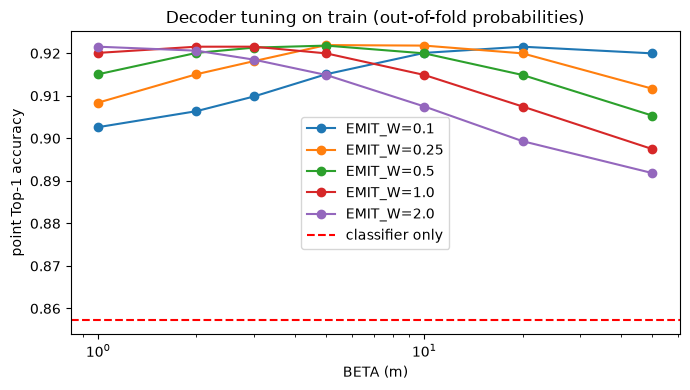

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for ew, g in grid.groupby("emit_w"): ax.plot(g.beta, g.hmm_top1, marker="o", label=f"EMIT_W={ew}")
ax.axhline(grid.clf_top1.iloc[0], color="r", ls="--", label="classifier only")
ax.set(xscale="log", title="Decoder tuning on train (out-of-fold probabilities)", xlabel="BETA (m)", ylabel="point Top-1 accuracy"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "plots/01_decoder_tuning.png", dpi=130); plt.show()

## 3. student_test: classifier-only vs classifier + HMM

In [6]:
res, pred = run("student_test", cte, pte, BETA, EMIT_W)
pred.to_parquet(OUT / "student_test_predictions.parquet", index=False)
cont = {}
for col in ["clf_arc", "hmm_arc"]:
    pp = pred[pred[col] >= 0].rename(columns={col: "arc_id"})
    cont[col] = route_continuity(pp, pte, arcs)
pr_ = pooled(res)
summary = pd.DataFrame({"classifier only": [pr_["clf_top1"], pr_["clf_road_acc"], pr_["clf_route_f1"], cont["clf_arc"], np.nan],
                        "classifier + HMM": [pr_["hmm_top1"], pr_["hmm_road_acc"], pr_["hmm_route_f1"], cont["hmm_arc"], res.breaks.sum()]},
                       index=["point Top-1 accuracy (strict arc)", "road-level accuracy (either direction)", "route arc F1 (mean per trip)",
                              "route continuity", "chain breaks"])
summary.to_csv(OUT / "student_test_summary.csv"); res.to_csv(OUT / "student_test_per_trip.csv", index=False)
print(summary.round(4)); res.round(4)

                                        classifier only  classifier + HMM
point Top-1 accuracy (strict arc)                0.8820            0.9369
road-level accuracy (either direction)           0.9364            0.9666
route arc F1 (mean per trip)                     0.9058            0.9620
route continuity                                 0.9499            0.9817
chain breaks                                        NaN            6.0000


,trip_id,points,labelled,breaks,decode_s,clf_top1,hmm_top1,clf_road_acc,hmm_road_acc,clf_route_f1,hmm_route_f1
0,00000000,2503,2503,2,0.0442,0.9481,0.9816,0.9525,0.9884,0.8953,0.9719
1,00000007,1354,1354,0,0.0194,0.9424,0.9542,0.9941,1.0000,0.9837,0.9959
2,00000009,1049,1049,0,0.0610,0.8723,0.8999,0.9037,0.9218,0.9191,0.9402
3,00000040,2995,2995,0,0.0583,0.9429,0.9753,0.9699,0.9813,0.9128,0.9933
4,00000052,262,262,0,0.0075,0.9695,1.0000,0.9695,1.0000,0.9405,1.0000
5,00000056,3958,3931,2,0.1246,0.9077,0.9519,0.9201,0.9596,0.9480,0.9717
6,00000065,768,768,2,0.0289,0.8424,0.8815,0.9141,0.9622,0.8817,0.9552
7,00000076,1486,1486,0,0.0834,0.8849,0.9536,0.9011,0.9616,0.8453,0.9182
8,00000077,3911,3911,0,0.1529,0.7497,0.8668,0.9274,0.9547,0.8252,0.9328
9,00000091,874,874,0,0.0358,0.8833,0.9416,0.9085,0.9428,0.9063,0.9412


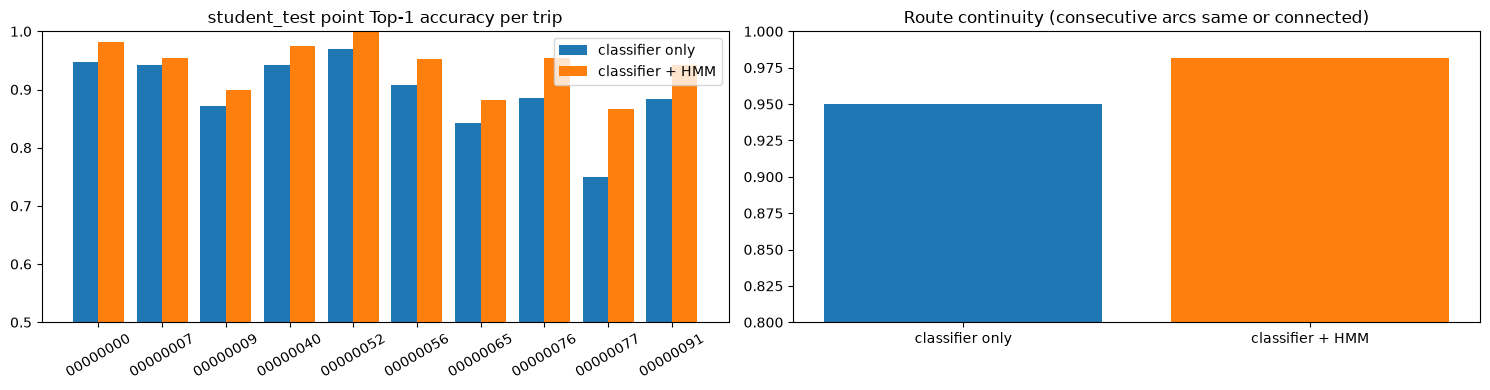

trips where HMM did not help: none


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
x = np.arange(len(res))
ax[0].bar(x - .2, res.clf_top1, .4, label="classifier only"); ax[0].bar(x + .2, res.hmm_top1, .4, label="classifier + HMM")
ax[0].set_xticks(x, res.trip_id, rotation=30); ax[0].set(title="student_test point Top-1 accuracy per trip", ylim=(0.5, 1)); ax[0].legend()
ax[1].bar(["classifier only", "classifier + HMM"], [cont["clf_arc"], cont["hmm_arc"]], color=["tab:blue", "tab:orange"])
ax[1].set(title="Route continuity (consecutive arcs same or connected)", ylim=(0.8, 1))
plt.tight_layout(); plt.savefig(OUT / "plots/02_clf_vs_hmm.png", dpi=130); plt.show()
worse = res[res.hmm_top1 < res.clf_top1]
print("trips where HMM did not help:", list(worse.trip_id) or "none")

## 3b. Why strict accuracy has a ceiling: reference labels against the travel direction
On a two-way road the two directions are separate arcs with identical geometry. We measure how often the *reference* arc of a point
points opposite to the GPS travel direction (heading difference > 135 degrees while moving > 3 m/s). Those labels contradict the GPS,
so a decoder that follows the real direction is scored wrong there. This is why we also report **road-level accuracy** (correct road,
either direction) next to the strict arc-level accuracy.

In [8]:
for part, c in [("train", ctr), ("student_test", cte)]:
    t = c[(c.label == 1) & (c.speed > 3)]
    print(f"{part}: {(t.heading_diff > 135).mean():.2%} of labelled moving points have a reference arc pointing against travel")

train: 3.22% of labelled moving points have a reference arc pointing against travel
student_test: 3.02% of labelled moving points have a reference arc pointing against travel


## 4. Folium maps: GPS, road network, reference route, classifier-only and HMM routes

In [9]:
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"
def route_map(part, tid, pred_df):
    trip = load_trip(part, tid); tr, nd, ar = trip["track"], trip["nodes"], trip["arcs"]
    q = pred_df[pred_df.trip_id == tid]
    seg = lambda ids: [[[nd.lat[ar.u[i]], nd.lon[ar.u[i]]], [nd.lat[ar.v[i]], nd.lon[ar.v[i]]]] for i in ids]
    m = folium.Map(tiles=None); folium.TileLayer(ESRI, attr="Tiles &copy; Esri", name="Esri street map").add_to(m)
    layers = [("Reference route", trip["route"].arc_id.values, "green", 8, .45),
              ("Classifier-only prediction", np.unique(q.clf_arc[q.clf_arc >= 0]), "red", 3, .9),
              ("HMM prediction", np.unique(q.hmm_arc[q.hmm_arc >= 0]), "blue", 4, .9)]
    for name, ids, col, w, op in layers:
        fg = folium.FeatureGroup(name); folium.PolyLine(seg(ids), color=col, weight=w, opacity=op).add_to(fg); fg.add_to(m)
    fg = folium.FeatureGroup("GPS observations"); step = max(1, len(tr) // 3000)
    for i in range(0, len(tr), step):
        folium.CircleMarker([tr.lat[i], tr.lon[i]], radius=2, color="black", fill=True, weight=0, fill_opacity=.6).add_to(fg)
    fg.add_to(m); folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([[tr.lat.min(), tr.lon.min()], [tr.lat.max(), tr.lon.max()]])
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px;border:1px solid #888;font:13px sans-serif">'
        f'<b>{part}/{tid}</b><br><span style="color:green">&#9644;</span> reference route<br><span style="color:red">&#9644;</span> classifier only<br>'
        f'<span style="color:blue">&#9644;</span> HMM prediction<br>&#9679; GPS</div>'))
    m.save(OUT / "maps" / f"hmm_{part}_{tid}.html"); return m

for tid in res.trip_id: m_ = route_map("student_test", tid, pred)
gain = (res.hmm_top1 - res.clf_top1).idxmax()
route_map("student_test", res.trip_id[gain], pred)

In [10]:
json.dump({"beta": BETA, "emit_w": EMIT_W, "min_prob": hmm.MIN_PROB, "back_tol_m": hmm.BACK_TOL, "gap_split_s": cfg["gap_split_s"],
           "tuned_on": "train out-of-fold probabilities (GroupKFold 5)"}, open(ART / "hmm_config.json", "w"), indent=2)
print("saved artifacts/hmm_config.json")

saved artifacts/hmm_config.json
